# Network analysis

This notebook measures the walk graph of Vasilyevsky Island: statistics of the whole network and of a grid of zones, measures around every node, residents within a walking time, the nearest objects, diversity and centralities. The buildings come from `data/spb_buildings.parquet`, which covers the south-eastern part of the island.

In [1]:
# To install IduEdu in a clean environment:
# !pip install IduEdu

OSM_ID = 1114252  # Vasilyevsky Island, Saint Petersburg

In [2]:
import geopandas as gpd
import numpy as np

import iduedu

walk = iduedu.get_walk_graph(osm_id=OSM_ID, clip_by_territory=True)
walk

UrbanGraph(nodes=22289, edges=29149, is_multigraph=True, is_directed=False, edge_direction_column=None, crs='EPSG:32636', type='walk')

In [3]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
STREETS = "#d6d4ce"


def basemap(ax, graph, title):
    graph.edges_gdf.plot(ax=ax, color=STREETS, linewidth=0.4, zorder=1)
    ax.set_title(title)
    ax.set_axis_off()

## Statistics of the whole network

`graph_stats` counts streets, not stored edges: an undirected connection between two nodes once, with lengths taken on the unique segments of the geometry.

In [4]:
stats = iduedu.graph_stats(walk)
stats.round(3)

node_count                  22289.000
edge_count                  29149.000
street_count                29142.000
street_length_total        725863.903
street_length_mean             24.904
streets_per_node_mean           2.615
dead_end_count               4878.000
dead_end_share                  0.219
intersection_count          14244.000
intersection_4way_share         0.297
circuity_mean                   1.045
self_loop_share                 0.001
parallel_street_share           0.011
component_count                 1.000
largest_component_share         1.000
beta_index                      1.307
gamma_index                     0.436
cyclomatic_number            6854.000
meshedness                      0.154
orientation_entropy             3.268
orientation_order               0.267
speed_mean_kmh                  5.000
Name: value, dtype: float64

## Statistics by zone

`zones` measures every zone separately. Here the zones are squares of 500 m; squares with less than half of their area on land are left out, because their densities are unstable.

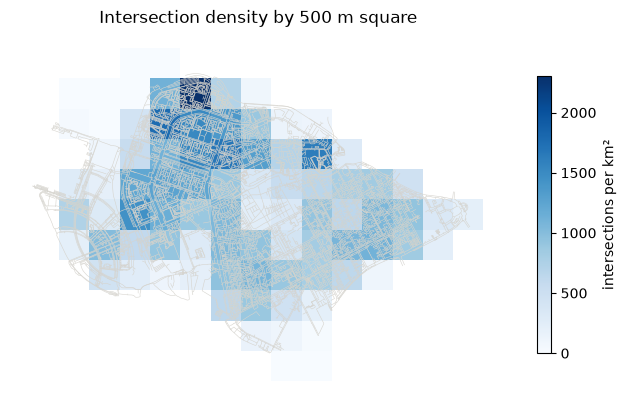

In [5]:
from shapely.geometry import box

area = iduedu.get_4326_boundary(osm_id=OSM_ID)
area = gpd.GeoSeries([area], crs=4326).to_crs(walk.crs).iloc[0]
minx, miny, maxx, maxy = area.bounds
cells = [box(x, y, x + 500, y + 500) for x in np.arange(minx, maxx, 500) for y in np.arange(miny, maxy, 500)]
grid = gpd.GeoDataFrame(geometry=cells, crs=walk.crs)
grid = grid[grid.intersection(area).area > 0.5 * 500 * 500].reset_index(drop=True)

by_square = iduedu.graph_stats(walk, zones=grid)
grid['intersection_density'] = by_square['intersection_density'].to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
grid.plot(ax=ax, column='intersection_density', cmap='Blues', legend=True,
          legend_kwds={'label': 'intersections per km²', 'shrink': 0.6})
basemap(ax, walk, 'Intersection density by 500 m square')
plt.show()

## Measures around every node

`local_stats` runs a cut-off search from every node; several radii come from the same searches.

In [6]:
local = iduedu.local_stats(walk, [400, 800])
local[['street_length_400', 'intersections_per_km_400', 'street_length_800']].describe().round(1)

,street_length_400,intersections_per_km_400,street_length_800
count,22289.0,22289.0,22289.0
mean,11644.8,22.3,45738.9
std,4057.9,6.0,13862.5
min,202.9,0.0,447.0
25%,9191.5,18.7,37338.1
50%,12020.4,21.5,47792.2
75%,14575.4,26.1,54898.7
max,23018.3,44.0,79298.8


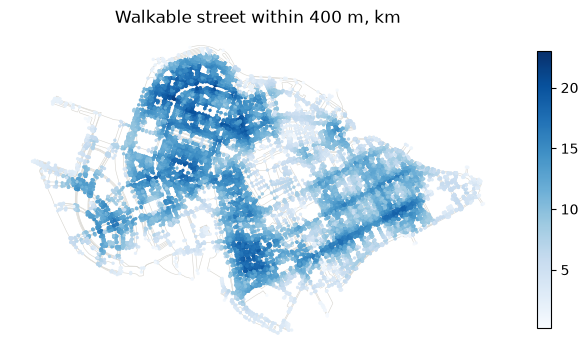

In [7]:
xy = walk.nodes_gdf.loc[local.index].geometry
fig, ax = plt.subplots(figsize=(8, 6))
basemap(ax, walk, 'Walkable street within 400 m, km')
points = ax.scatter(xy.x, xy.y, c=local['street_length_400'] / 1000, cmap='Blues', s=2)
fig.colorbar(points, ax=ax, shrink=0.6)
plt.show()

## Residents within a walking time

`aggregate_objects` counts objects and sums their columns within one or several travel costs of every origin. Here every node of the graph is an origin and the residential buildings are the objects; the buildings are matched to their nearest nodes.

In [8]:
buildings = gpd.read_parquet('data/spb_buildings.parquet').to_crs(walk.crs)
homes = buildings[buildings['resident_number'].fillna(0) > 0]

residents = iduedu.aggregate_objects(
    walk, [5, 10, 15], origins_nodes=walk.nodes_gdf.index, gdf_objects=homes, columns=['resident_number']
)
residents[['count_10', 'resident_number_sum_5', 'resident_number_sum_10', 'resident_number_sum_15']].describe().round(0)

,count_10,resident_number_sum_5,resident_number_sum_10,resident_number_sum_15
count,22289.0,22289.0,22289.0,22289.0
mean,37.0,662.0,2875.0,5745.0
std,69.0,1414.0,5207.0,9069.0
min,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0
75%,31.0,80.0,2875.0,11105.0
max,283.0,6674.0,21386.0,30287.0


With `decay` every building counts with a weight that falls with the walking time. The exponential decay leaves a weight of 0.018 at the cutoff by default.

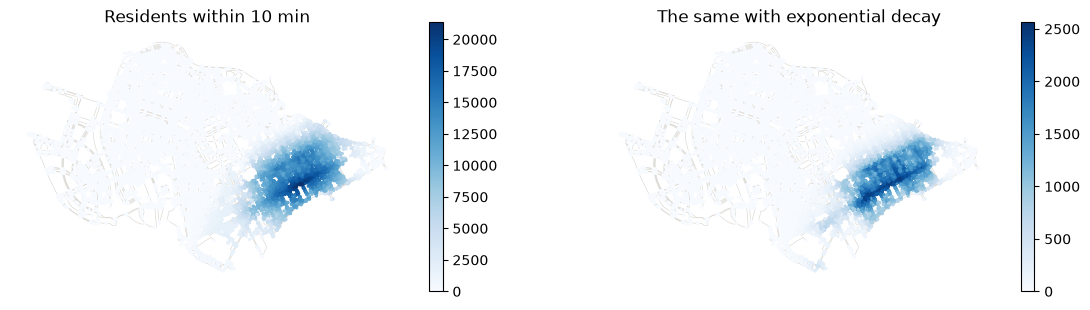

In [9]:
weighted = iduedu.aggregate_objects(
    walk, 10, origins_nodes=walk.nodes_gdf.index, gdf_objects=homes, columns=['resident_number'], decay='exp'
)
xy = walk.nodes_gdf.loc[weighted.index].geometry
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, values, title in (
    (axes[0], residents['resident_number_sum_10'], 'Residents within 10 min'),
    (axes[1], weighted['resident_number_sum_10'], 'The same with exponential decay'),
):
    basemap(ax, walk, title)
    points = ax.scatter(xy.x, xy.y, c=values.fillna(0), cmap='Blues', s=2)
    fig.colorbar(points, ax=ax, shrink=0.7)
plt.show()

## The nearest objects

`nearest_objects` stops the search of every origin once `k` objects are found. As an example, 25 non-residential buildings stand in for services, and every residential building looks for its three nearest ones.

In [10]:
services = buildings[buildings['resident_number'].fillna(0) == 0].sample(25, random_state=1)
nearest = iduedu.nearest_objects(walk, gdf_origins=homes, gdf_objects=services, k=3)
nearest.head(6)

object      dist
origin rank                  
15     1        972  5.766000
       2       1037  6.193000
       3         21  8.015000
16     1        626  4.969000
       2        614  5.776000
       3        604  8.558001

In [11]:
first = nearest.xs(1, level='rank')['dist']
print(f'median walk to the nearest service: {first.median():.1f} min, '
      f'to the third nearest: {nearest.xs(3, level="rank")["dist"].median():.1f} min')

median walk to the nearest service: 4.9 min, to the third nearest: 9.6 min


## Diversity

`diversity` measures how mixed the categories of the objects in reach are. Here the category is the height class of a building; `hill_c` is the effective number of equally common classes (the inverse Simpson index by default).

In [12]:
heights = buildings.assign(
    height_class=np.select(
        [buildings['storeys_count'] <= 3, buildings['storeys_count'] <= 6], ['low', 'mid'], default='high'
    )
)
mix = iduedu.diversity(walk, 10, 'height_class', gdf_objects=heights, gdf_origins=homes)
mix.describe().round(2)

,richness_10,shannon_10,hill_10
count,433.0,433.00,433.00
mean,3.0,1.09,2.93
std,0.0,0.02,0.07
min,3.0,0.88,2.25
25%,3.0,1.09,2.92
50%,3.0,1.09,2.94
75%,3.0,1.09,2.97
max,3.0,1.10,3.00


## Centrality

`centrality` computes reach, harmonic closeness and gravity within thresholds measured by `length_meter`; `edge_betweenness` counts the shortest paths within a threshold along every edge.

In [13]:
nodes = iduedu.centrality(walk, ['reach', 'harmonic', 'gravity'], cutoffs=[400, 800])
edges = iduedu.edge_betweenness(walk, cutoffs=2000)
nodes.describe().round(2)

,reach_400,reach_800,harmonic_400,harmonic_800,gravity_400,gravity_800
count,22289.00,22289.00,22289.00,22289.00,22289.00,22289.00
mean,412.91,1568.55,2.50,4.43,51.84,188.62
std,187.59,602.65,1.26,1.75,26.52,77.65
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,271.00,1183.00,1.62,3.22,32.72,131.65
50%,424.00,1621.00,2.41,4.55,50.30,196.27
75%,548.00,1979.00,3.22,5.64,67.65,244.07
max,928.00,3229.00,9.70,11.98,148.14,384.71


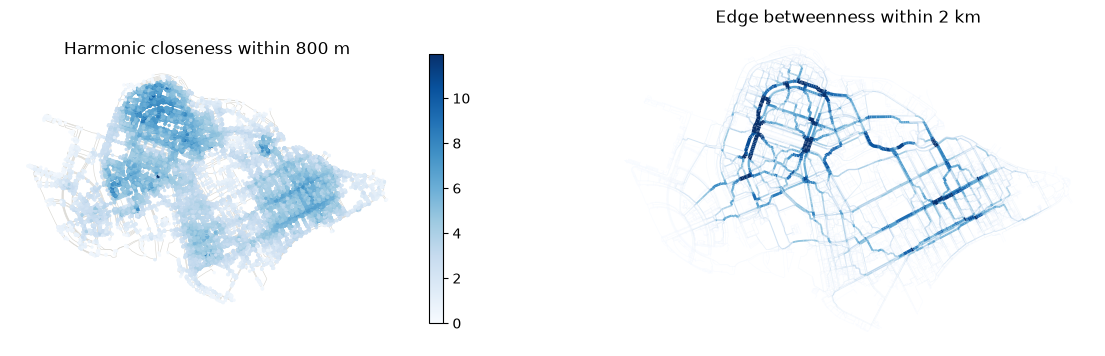

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
xy = walk.nodes_gdf.loc[nodes.index].geometry
basemap(axes[0], walk, 'Harmonic closeness within 800 m')
points = axes[0].scatter(xy.x, xy.y, c=nodes['harmonic_800'], cmap='Blues', s=2)
fig.colorbar(points, ax=axes[0], shrink=0.7)

lines = walk.edges_gdf.assign(b=edges['betweenness_2000'].to_numpy()).sort_values('b')
top = lines['b'].quantile(0.995)
lines.plot(ax=axes[1], column='b', cmap='Blues', vmax=top, linewidth=0.3 + 2.5 * (lines['b'] / top).clip(0, 1))
axes[1].set_title('Edge betweenness within 2 km')
axes[1].set_axis_off()
plt.show()

## Your own area

Replace `OSM_ID` with the id of an OSM boundary relation, or pass `territory=` a shapely polygon in EPSG:4326 or a
GeoDataFrame. Measures near the border of a graph are biased, because the network beyond it is missing: build the
graph for a larger area and pass the study area as `area=` to `graph_stats` and `centrality`. For many runs on one
region, read a local OSM file instead of Overpass with `iduedu.use_pbf(...)` (see the data sources page).